In [165]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const

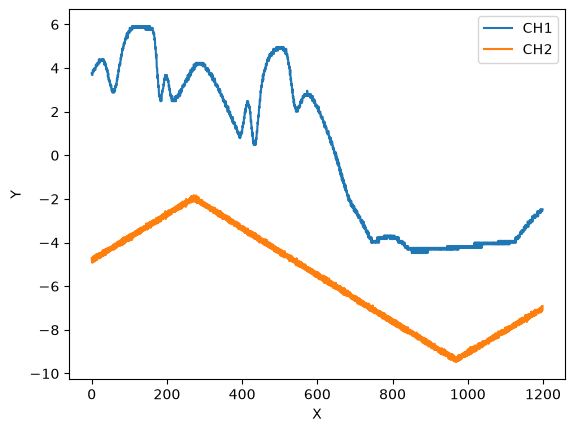

In [166]:
data = np.loadtxt('data\\NewFile1.csv', delimiter=',', skiprows=2, dtype=str)
X = data[0:, 0]  # Assuming the first column is X values
CH1 = data[0:, 1]  # Assuming the second column is Y values
CH2 = data[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1 = CH1.astype(float)
CH2 = CH2.astype(float)

# plot
plt.plot(X, CH1, label='CH1')
plt.plot(X, CH2, label='CH2')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [167]:
print(CH2[0])
print(np.max(CH2) - np.min(CH2))

-4.72
7.640000000000001


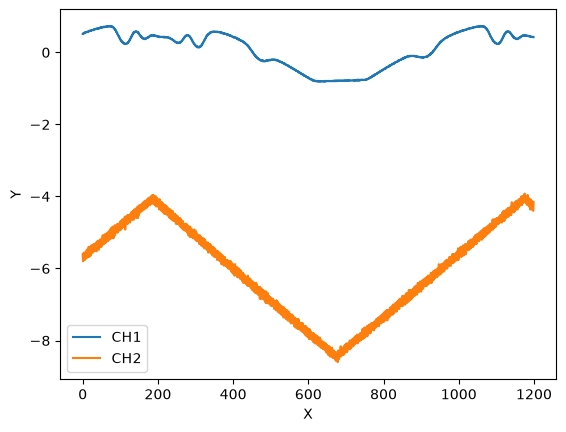

In [168]:
data = np.loadtxt('data\\NewFile7.csv', delimiter=',', skiprows=2, dtype=str)
X = data[0:, 0]  # Assuming the first column is X values
CH1 = data[0:, 1]  # Assuming the second column is Y values
CH2 = data[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1 = CH1.astype(float)
CH2 = CH2.astype(float)

# plot
plt.plot(X, CH1, label='CH1')
plt.plot(X, CH2, label='CH2')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

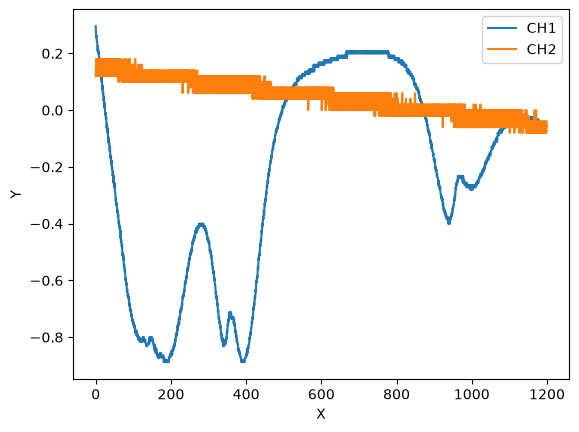

In [169]:
data = np.loadtxt('data\\NewFile17.csv', delimiter=',', skiprows=2, dtype=str)
X = data[0:, 0]  # Assuming the first column is X values
CH1 = data[0:, 1]  # Assuming the second column is Y values
CH2 = data[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1 = CH1.astype(float)
CH2 = CH2.astype(float)

# plot
plt.plot(X, CH1, label='CH1')
plt.plot(X, CH2, label='CH2')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

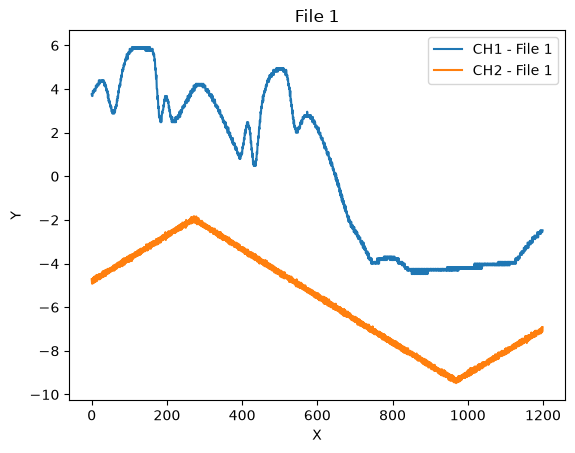

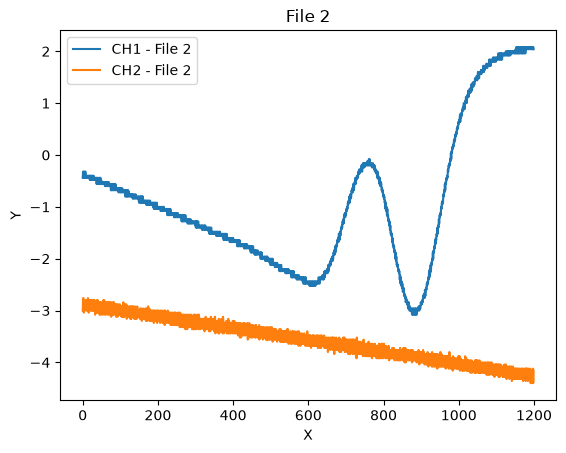

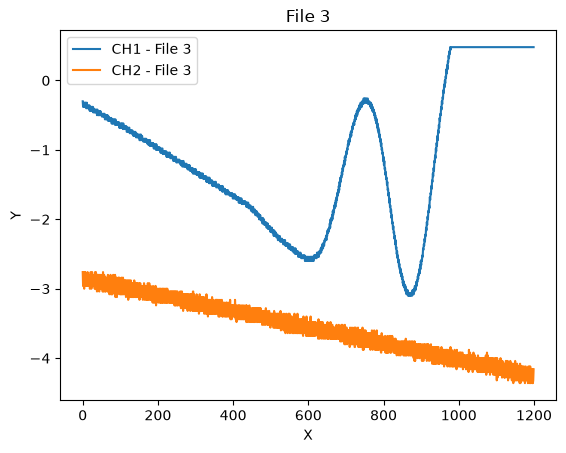

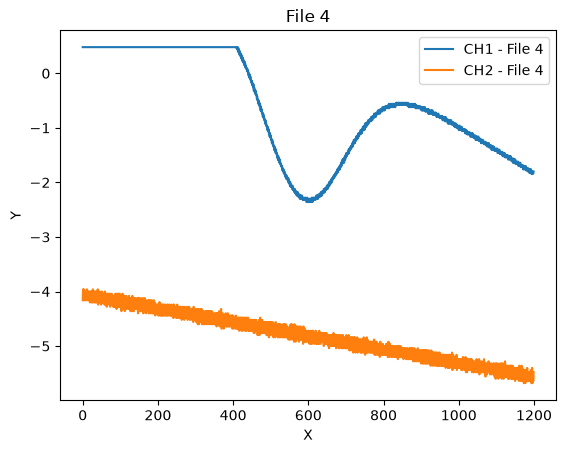

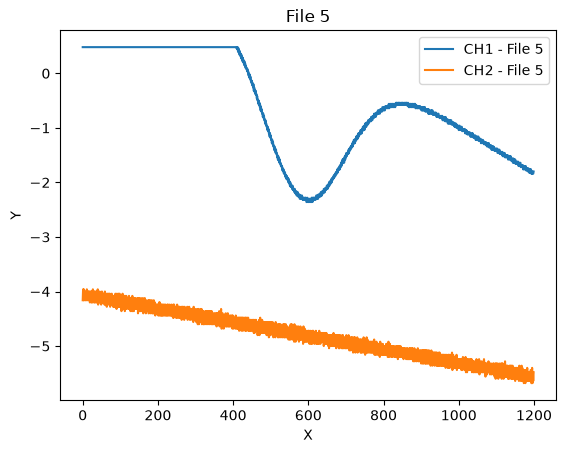

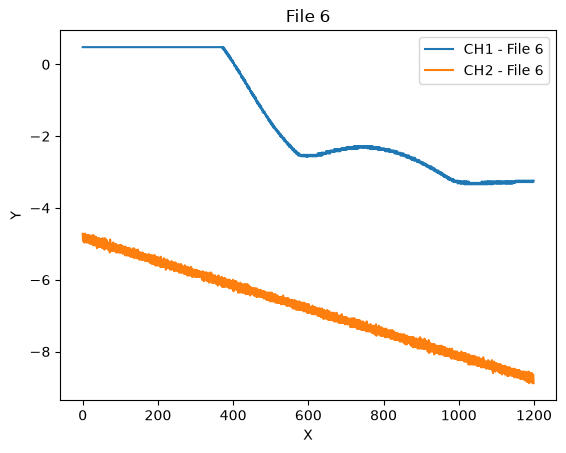

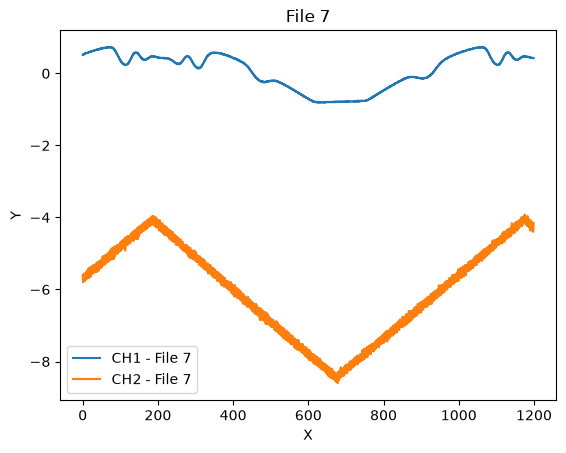

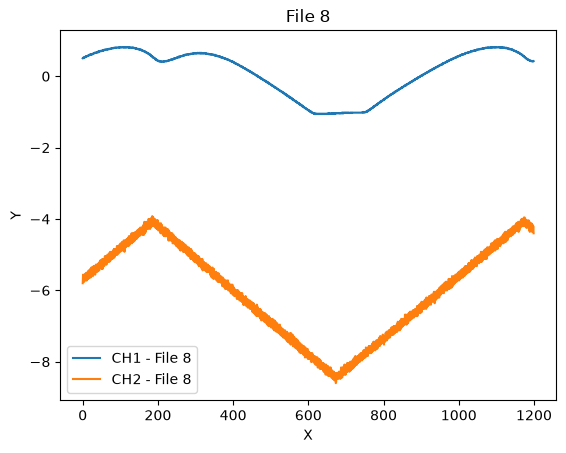

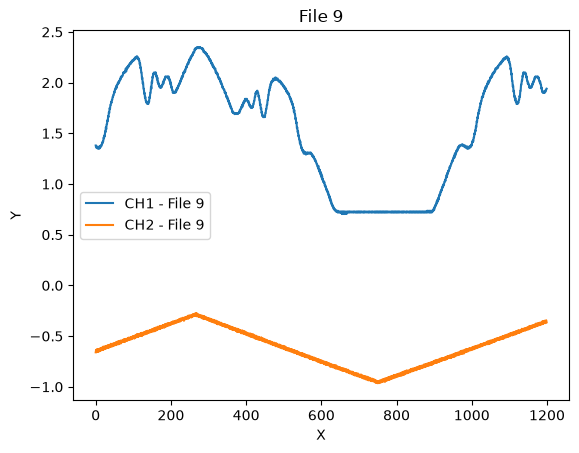

In [ ]:
for i in range(1, 18):
    filename = f'data\\NewFile{i}.csv'
    data = np.loadtxt(filename, delimiter=',', skiprows=2, dtype=str)
    X = data[0:, 0]  # Assuming the first column is X values
    CH1 = data[0:, 1]  # Assuming the second column is Y values
    CH2 = data[0:, 2]  # Assuming the third column is Y values

    X = X.astype(float)
    CH1 = CH1.astype(float)
    CH2 = CH2.astype(float)

    # plot
    plt.title(f'File {i}')
    plt.plot(X, CH1, label=f'CH1 - File {i}')
    plt.plot(X, CH2, label=f'CH2 - File {i}')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.legend()
    plt.show()


Doppler broadened spectrum with background correction

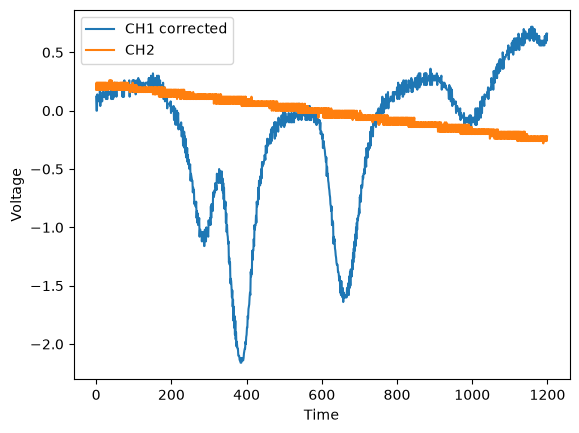

In [ ]:
dataA = np.loadtxt('data\\NewFile11.csv', delimiter=',', skiprows=2, dtype=str)
dataB = np.loadtxt('data\\NewFile12.csv', delimiter=',', skiprows=2, dtype=str)
X = dataA[0:, 0]  # Assuming the first column is X values
CH1A = dataA[0:, 1]  # Assuming the second column is Y values
CH1B = dataB[0:, 1]  # Assuming the second column is Y values
CH2 = dataA[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1A = CH1A.astype(float)
CH1B = CH1B.astype(float)
CH2 = CH2.astype(float)

y_corrected = CH1A - CH1B

# plot
plt.plot(X, y_corrected, label='CH1 corrected')
plt.plot(X, CH2, label='CH2')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.show()

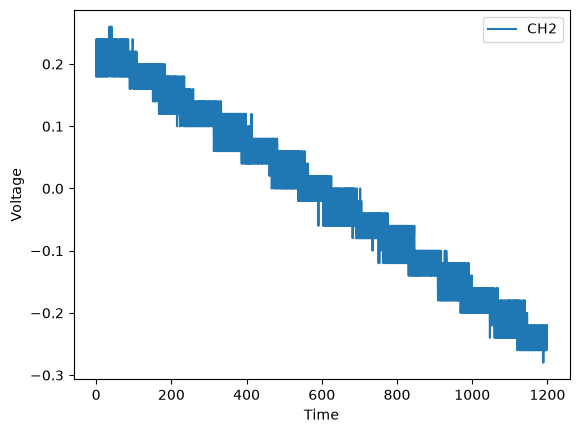

In [ ]:
# plot
plt.plot(X, CH2, label='CH2')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.show()

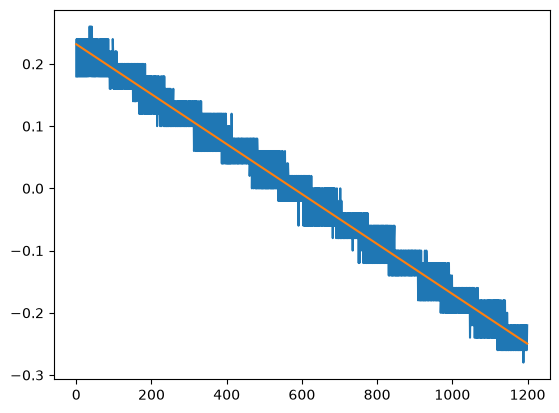

In [ ]:
# linear fit
CH2_linear = np.polyfit(X, CH2, deg=1)
V = np.polyval(CH2_linear, X)

plt.plot(X, CH2, label='CH2')
plt.plot(X, V, label='CH2 linear fit')

In [ ]:
from scipy.signal import find_peaks

# Find minima by detecting peaks in the inverted signal
minima_indices, properties = find_peaks(
    -y_corrected,
    prominence=0.2,
    distance=50
)

# Show minima from left to right
minima_indices = minima_indices[np.argsort(X[minima_indices])]

for i in minima_indices:
    print(f"X = {X[i]:.0f}, Y = {y_corrected[i]:.2f}")

# find the corresponding voltage frequency sweep values
peak_voltages = V[minima_indices]
print("Peak voltages:", peak_voltages)


X = 287, Y = -1.16
X = 385, Y = -2.16
X = 657, Y = -1.64
X = 992, Y = -0.14
Peak voltages: [ 0.11648379  0.07715821 -0.03199035 -0.16641964]


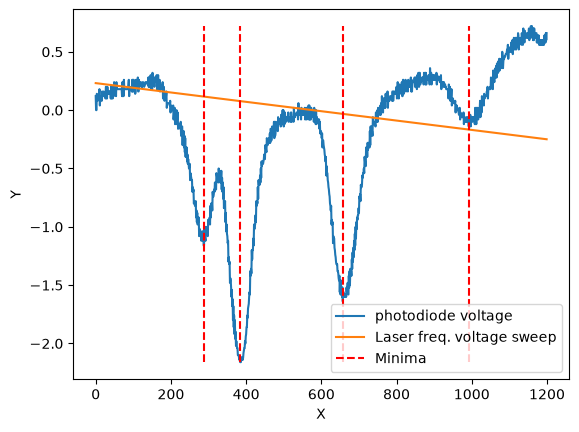

In [ ]:
# plot
plt.plot(X, y_corrected, label='photodiode voltage')
plt.plot(X, V, label='Laser freq. voltage sweep')
plt.vlines(X[minima_indices], ymin=np.min(y_corrected), ymax=np.max(y_corrected), color='r', linestyle='--', label='Minima')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [ ]:
f_peaks = []

In [ ]:
# peak 1 freq value (source:https://steck.us/alkalidata/)
peak1freq = 384230.484468 - 2.56300597908 #GHz
f_peaks.append(peak1freq)
print(f"Peak 1 frequency: {peak1freq:.6f} GHz")

Peak 1 frequency: 384227.921462 GHz


In [ ]:
# peak 2 freq value (source:https://steck.us/alkalidata/)
peak2freq = 384230.406373 - 1.2648885163 #GHz
f_peaks.append(peak2freq)
print(f"Peak 2 frequency: {peak2freq:.6f} GHz")

Peak 2 frequency: 384229.141484 GHz


In [ ]:
# peak 3 freq value (source:https://steck.us/alkalidata/)
peak3freq = 384230.406373 + 1.7708439228
f_peaks.append(peak3freq)
print(f"Peak 3 frequency: {peak3freq:.6f} GHz")

Peak 3 frequency: 384232.177217 GHz


In [ ]:
# peak 4 freq value (source:https://steck.us/alkalidata/)
peak4freq = 384230.4844685 + 4.27167663182
f_peaks.append(peak4freq)
print(f"Peak 4 frequency: {peak4freq:.6f} GHz")

Peak 4 frequency: 384234.756145 GHz


In [ ]:
print(f_peaks)

[384227.92146202095, 384229.1414844837, 384232.1772169228, 384234.75614513183]


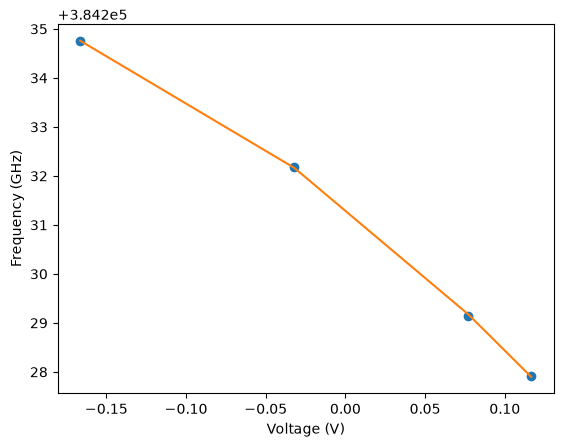

Slope method 2: -24.159067781612215


In [ ]:
# Fit a line
poly_coeffs = np.polyfit(peak_voltages, f_peaks, deg=2)
calibration_func = np.poly1d(poly_coeffs)

plt.plot(peak_voltages, f_peaks, 'o', label='Data points')
plt.plot(peak_voltages, calibration_func(peak_voltages), label='Polynomial fit')
plt.xlabel('Voltage (V)')   
plt.ylabel('Frequency (GHz)')
plt.show()

# print("Slope:", poly_coeffs[0])
print("Slope method 2:", (f_peaks[-1] - f_peaks[0]) / (peak_voltages[-1] - peak_voltages[0]))

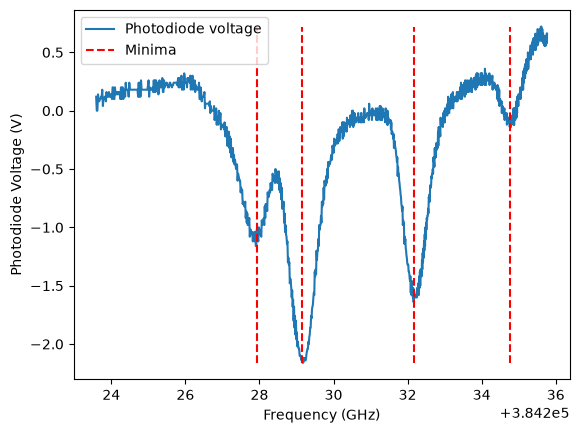

In [ ]:
f_range = calibration_func(V)

plt.plot(f_range, y_corrected, label='Photodiode voltage')
plt.vlines(f_peaks, ymin=np.min(y_corrected), ymax=np.max(y_corrected), color='r', linestyle='--', label='Minima')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Photodiode Voltage (V)')
plt.legend()
plt.show()


In [ ]:
masses = np.array([87, 85, 85, 87]) * const.m_u  # Convert atomic mass units to kg
FWHMs = np.array([580.55e6, 802.74e6, 748.11e6, 616.38e6]) # Hz
f_peaks = np.array(f_peaks) * 1e9  # Convert GHz to Hz

temps = [
    (FWHMs[i] / (2 * f_peaks[i]))**2 * (masses[i] * const.c**2) / (const.k * 2 * np.log(2)) 
    for i in range(4)
]

print(temps)

[np.float64(387.1795776790131), np.float64(723.2357847840492), np.float64(628.1366811663711), np.float64(436.4302144780978)]


Doppler free spectrum

Peak 1

In [ ]:
dataA = np.loadtxt('data\\NewFile13.csv', delimiter=',', skiprows=2, dtype=str)
dataB = np.loadtxt('data\\NewFile14.csv', delimiter=',', skiprows=2, dtype=str)
X = dataA[0:, 0]  # Assuming the first column is X values
CH1A = dataA[0:, 1]  # Assuming the second column is Y values
CH1B = dataB[0:, 1]  # Assuming the second column is Y values
CH2 = dataA[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1A = CH1A.astype(float)
CH1B = CH1B.astype(float)
CH2 = CH2.astype(float)

y_corrected = CH1A - CH1B

In [ ]:
# linear fit V
CH2_linear = np.polyfit(X, CH2, deg=1)
V = np.polyval(CH2_linear, X)

plt.plot(X, CH2, label='CH2')
plt.plot(X, V, label='CH2 linear fit')

In [ ]:
from scipy.signal import find_peaks

# Find minima by detecting peaks in the inverted signal
minima_indices, properties = find_peaks(
    -y_corrected,
    prominence=0.2,
    distance=50
)

# Show minima from left to right
minima_indices = minima_indices[np.argsort(X[minima_indices])]

for i in minima_indices:
    print(f"X = {X[i]:.0f}, Y = {y_corrected[i]:.2f}")

# find the corresponding voltage frequency sweep values
peak_voltages = V[minima_indices]
print("Peak voltages:", peak_voltages)


X = 361, Y = -0.30
X = 645, Y = -0.81
X = 732, Y = -0.88
Peak voltages: [ 0.08678896 -0.02717497 -0.06208646]


In [ ]:
# Fit a line V to freq peaks
poly_coeffs_2 = np.polyfit(peak_voltages, f_peaks, deg=2)
calibration_func_2 = np.poly1d(poly_coeffs_2)

plt.plot(peak_voltages, f_peaks, 'o', label='Data points')
plt.plot(peak_voltages, calibration_func_2(peak_voltages), label='Polynomial fit')
plt.xlabel('Voltage (V)')   
plt.ylabel('Frequency (GHz)')
plt.show()

# print("Slope:", poly_coeffs[0])
print("Slope method 2:", (f_peaks[-1] - f_peaks[0]) / (peak_voltages[-1] - peak_voltages[0]))

TypeError: expected x and y to have same length

In [ ]:
# plot
plt.plot(f_range[0:350], y_corrected[0:350], label='CH1 corrected')
# plt.plot(X[0:500], CH2[0:500], label='CH2')
plt.title('Saturated Absorption Doppler Free Spectrum 87Rb F=2')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Voltage (V)')
plt.legend()
plt.show()

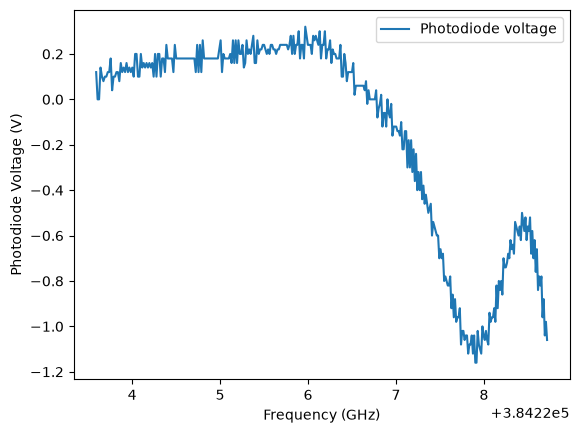

In [ ]:
dataA = np.loadtxt('data\\NewFile11.csv', delimiter=',', skiprows=2, dtype=str)
dataB = np.loadtxt('data\\NewFile12.csv', delimiter=',', skiprows=2, dtype=str)
X = dataA[0:, 0]  # Assuming the first column is X values
CH1A = dataA[0:, 1]  # Assuming the second column is Y values
CH1B = dataB[0:, 1]  # Assuming the second column is Y values
CH2 = dataA[0:, 2]  # Assuming the third column is Y values

X = X.astype(float)
CH1A = CH1A.astype(float)
CH1B = CH1B.astype(float)
CH2 = CH2.astype(float)

y_corrected = CH1A - CH1B

f_range = calibration_func(V)

plt.plot(f_range[0:350], y_corrected[0:350], label='Photodiode voltage')
plt.xlabel('Frequency (GHz)')
plt.ylabel('Photodiode Voltage (V)')
plt.legend()
plt.show()
